In [2]:
import numpy as np
import h5py
import matplotlib.pyplot as plt
import copy

In [3]:
np.random.seed(1)

In [4]:
def sigmoid(x):
    s = 1 / (np.exp(-x) + 1)
    activation_cache = x
    return s, activation_cache

In [5]:
def sigmoid_backward(dA, activation_cache):
    Z = activation_cache
    s = 1 / (1 + np.exp(-Z))
    dZ = dA * s * (1 - s)
    return dZ

In [6]:
def relu_backward(dA, activation_cache):
    Z = activation_cache
    dZ = np.array(dA, copy=True)
    dZ[Z <= 0] = 0
    
    return dZ

In [7]:
def relu(x):
    s = np.maximum(0, x)
    activation_cache = x
    return s, activation_cache

In [8]:
def initialize_parameters_zeros(layers_dims):
    parameters = {}
    for l in range(1, len(layers_dims)):
        parameters['W' + str(l)] = np.zeros((layers_dims[l], layers_dims[l -1]))
        parameters['b' + str(l)] = np.zeros((layers_dims[l], 1))
    return parameters

In [9]:
def initialize_parameters_random(layers_dims):
    np.random.seed(5)
    parameters = {}
    for l in range(1, len(layers_dims)):
        parameters['W' + str(l)] = np.random.randn(layers_dims[l], layers_dims[l - 1]) * 10
        parameters['b' + str(l)] = np.zeros((layers_dims[l], 1))
    return parameters

In [10]:
def initialize_parameters_he(layers_dims):
    np.random.seed(3)
    parameters = {}
    L = len(layers_dims) - 1
    for l in range(1, L + 1):
        parameters['W' + str(l)] = np.random.randn(layers_dims[l], layers_dims[l - 1]) * np.sqrt(2 / layers_dims[l - 1])
        parameters['b' + str(l)] = np.zeros((layers_dims[l], 1)) 
    return parameters

In [ ]:
def initialize_velocity(parameters):
    L = len(parameters) // 2
    v = {}
    for l in range(1, L + 1):
        v["dW" + str(l)] = np.zeros(parameters['W' + str(l)].shape)
        v["db" + str(l)] = np.zeros(parameters['b' + str(l)].shape)
    return v

In [21]:
def initialize_adam(parameters):
    L = len(parameters) // 2
    v = {}
    s = {}
    for l in range(1, L + 1):
        v["dW" + str(l)] = np.zeros(parameters["W" + str(l)].shape)
        v["db" + str(l)] = np.zeros(parameters["b" + str(l)].shape)
        s["dW" + str(l)] = np.zeros(parameters["W" + str(l)].shape)
        s["db" + str(l)] = np.zeros(parameters["b" + str(l)].shape)
    return s, v 

In [11]:
def forward_propagation_with_dropout(X, parameters, keep_prob = 0.8, training = True):
    caches = []
    A = X 
    L = len(parameters) // 2
    for l in range(1, L):
        A_prev = A
        W = parameters['W' + str(l)]
        b = parameters['b' + str(l)]
        Z = np.dot(W, A_prev) + b
        A, _ = relu(Z)
        D = None
        if training and keep_prob < 1:
            D = (np.random.rand(*A.shape) < keep_prob)
            A = (A * D) / keep_prob
        caches.append({
            "A_prev" : A_prev,
            "Z" : Z,
            "W" : W, 
            "b" : b,
            "D" : D
        })
    W = parameters['W' + str(L)]
    b = parameters['b' + str(L)]

    ZL = np.dot(W, A) + b
    AL, _ = sigmoid(ZL)

    caches.append({
        "A_prev": A,
        "Z": ZL,
        "W": W,
        "b": b,
        "D": None
    })

    return AL, caches

In [12]:
def backward_propagation_with_dropout(AL, Y, caches, keep_prob = 0.8):
    grads = {}
    L = len(caches)
    m = Y.shape[1]
    Y = Y.reshape(AL.shape)

    output_cache = caches[-1]
    dZ = AL -Y
    A_prev = output_cache['A_prev']
    W = output_cache['W']

    grads['dW' + str(L)] = (1 / m) * np.dot(dZ, A_prev.T)
    grads['db' + str(L)] = (1 / m) * np.sum(dZ, axis = 1, keepdims = True)

    for l in reversed(range(1, L)):
        current_cache = caches[l - 1]
        next_cache = caches[l]
        dA = np.dot(next_cache['W'].T, dZ)
        D = current_cache['D']
        if D is not None:
            dA = (dA * D) / keep_prob

        Z = current_cache['Z']
        dZ = dA.copy()
        dZ[Z <= 0] = 0
        A_prev = current_cache['A_prev']
        
        grads['dW' + str(l)] = (1 / m) * np.dot(dZ, A_prev.T)
        grads['db' + str(l)] = (1 / m) * np.sum(dZ, axis = 1, keepdims = True)
    
    return grads

In [13]:
def compute_cost(AL, Y):
    m = Y.shape[1]
    cost = (-1/m) * np.sum(np.multiply(Y, np.log(AL + 1e-8)) + np.multiply(1 - Y, np.log(1 - AL + 1e-8)))
    cost = np.squeeze(cost)
    
    return cost

In [14]:
def compute_cost_with_regularization(AL, Y, parameters, lambd):
    m = Y.shape[1]
    cross_entropy_cost = compute_cost(AL, Y)

    L = len(parameters) // 2
    for l in range(1, L + 1):
        W = parameters['W' + str(l)]
        L2_regularization_cost = (np.sum(np.square(W))) * (lambd / (2 * m))
        cost =cross_entropy_cost + L2_regularization_cost

    return cost

In [15]:
def update_parameters(parameters, grads, learning_rate):
    updated = copy.deepcopy(parameters)
    L = len(parameters) // 2

    for l in range(1, L + 1):
        updated[f"W{l}"] -= learning_rate * grads[f"dW{l}"]
        updated[f"b{l}"] -= learning_rate * grads[f"db{l}"]

    return updated

In [16]:
def update_parameters_with_gd(parameters, grads, learning_rate):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        parameters["W" + str(l)] = parameters["W" +str(l)] - learning_rate * grads['dW' + str(l)]
        parameters["b" + str(l)] = parameters["b" + str(l)] - learning_rate * grads['db' + str(l)]

    return parameters

In [ ]:
def update_parameters_with_momentum(parameters, grads, v, beta, learning_rate):
    L = len(parameters) // 2
    for l in range(1, L + 1):
        v["dW" + str(l)] = beta * v["dW" + str(l)] + (1 - beta) *  grads['dW' + str(l)]
        v['db' + str(l)] = beta * v["db" + str(l)] + (1 - beta) *  grads['db' + str(l)]
        
        parameters["W" + str(l)] = parameters["W" + str(l)] - learning_rate * v["dW" + str(l)]
        parameters["b" + str(l)] = parameters["b" + str(l)] - learning_rate * v["db" + str(l)]
    return parameters, v

In [22]:
def update_parameters_with_adam(parameters, grads, v, s, t, learning_rate = 0.01,
                                beta1 = 0.9, beta2 = 0.999,  epsilon = 1e-8):
    L = len(parameters) // 2
    v_corrected = {}
    s_corrected = {}
    for l in range(1, L + 1):
        v["dW" + str(l)] = beta1 * v["dW" + str(l)] + (1 - beta1) * grads['dW' + str(l)]
        v["db" + str(l)] = beta1 * v["db" + str(l)] + (1 - beta1) * grads['db' + str(l)]

        v_corrected["dW" + str(l)] = v["dW" + str(l)] / (1 - pow(beta1, t))
        v_corrected["db" + str(l)] = v["db" + str(l)] / (1 - pow(beta1, t))

        s["dW" + str(l)] = beta2 * s["dW" + str(l)] + (1 - beta2) * pow(grads['dW' + str(l)], 2)
        s["db" + str(l)] = beta2 * s["db" + str(l)] + (1 - beta2) * pow(grads['db' + str(l)], 2)

        s_corrected["dW" + str(l)] = s["dW" + str(l)] / (1 - pow(beta2, t))
        s_corrected["db" + str(l)] = s["db" + str(l)] / (1 - pow(beta2, t))

        parameters["W" + str(l)] = parameters["W" + str(l)] - learning_rate * v_corrected["dW" + str(l)] / (np.sqrt(s_corrected["dW" + str(l)]) + epsilon)
        parameters["b" + str(l)] = parameters["b" + str(l)] - learning_rate * v_corrected["db" + str(l)] / (np.sqrt(s_corrected["db" + str(l)]) + epsilon)

    return parameters, v, s, v_corrected, s_corrected

In [23]:
def update_lr(learning_rate0, epoch_num, decay_rate):
    learning_rate = 1 / (1 + decay_rate * epoch_num) * learning_rate0

    return learning_rate

In [24]:
def schedule_lr_decay(learning_rate0, epoch_num, decay_rate, time_interval=1000):
    learning_rate = learning_rate0 / (1 + decay_rate * (epoch_num // time_interval)) 

    return learning_rate

In [17]:
def L_layer_model_v2(
    X, Y, layers_dims,
    learning_rate=0.0075,
    num_iterations=2500,
    lambd=0,
    keep_prob=1.0,
    print_cost=False
):
    parameters = initialize_parameters_he(layers_dims)
    costs = []

    for i in range(num_iterations):
        AL, caches = forward_propagation_with_dropout(
            X, parameters,
            keep_prob=keep_prob,
            training=True
        )

        cost = compute_cost_with_regularization(
            AL, Y, parameters, lambd
        )

        grads = backward_propagation_with_dropout(
            AL, Y, caches,
            keep_prob=keep_prob
        )

        if lambd > 0:
            L = len(parameters) // 2
            for l in range(1, L + 1):
                grads[f"dW{l}"] += (lambd / Y.shape[1]) * parameters[f"W{l}"]

        parameters = update_parameters(parameters, grads, learning_rate)

        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print(f"Cost after iteration {i}: {cost:.6f}")

    return parameters, costs  

In [18]:
def predict(X, Y, parameters):
    probabilities, _ = forward_propagation_with_dropout(
        X, parameters,
        keep_prob=1.0,
        training=False
    )

    predictions = (probabilities >= 0.5).astype(int)

    if Y is not None:
        print(f"Accuracy: {np.mean(predictions == Y):.4f}")

    return predictions

In [19]:
import cv2
import os

def load_and_preprocess_data(folder_path, label, image_size=(64, 64)):
    X = []
    Y = []
    for filename in os.listdir(folder_path):
        img_path = os.path.join(folder_path, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, image_size)
            X.append(img)
            Y.append(label)
            
    return X, Y

print("Loading data.....")
X_train_dogs, Y_train_dogs = load_and_preprocess_data('datasets/train/dogs', 1)
X_train_cats, Y_train_cats = load_and_preprocess_data('datasets/train/cats', 0)
X_test_dogs, Y_test_dogs = load_and_preprocess_data('datasets/test/dogs', 1)
X_test_cats, Y_test_cats = load_and_preprocess_data('datasets/test/cats', 0)
X_train_raw = np.array(X_train_dogs + X_train_cats)
Y_train= np.array(Y_train_dogs + Y_train_cats).reshape(1, -1)

X_test_raw = np.array(X_test_dogs + X_test_cats)
Y_test = np.array(Y_test_dogs + Y_test_cats).reshape(1, -1)

X_train = (X_train_raw.reshape(X_train_raw.shape[0], -1).T) / 255
X_test = (X_test_raw.reshape(X_test_raw.shape[0], -1).T) / 255

Loading data.....


In [20]:
parameters, costs = L_layer_model_v2(
    X_train, Y_train,
    layers_dims=[X_train.shape[0], 20, 7, 5, 1],
    learning_rate=0.0075,
    num_iterations=3000,
    lambd=0.1,
    keep_prob=0.8,
    print_cost=True
)
print("Train Accuracy: ")
predict(X_train, Y_train, parameters)
print("Test Accuracy: ")
predict(X_test, Y_test, parameters)

Cost after iteration 0: 0.771736
Cost after iteration 100: 0.692502


KeyboardInterrupt: 

Model y = 1
=> Dog


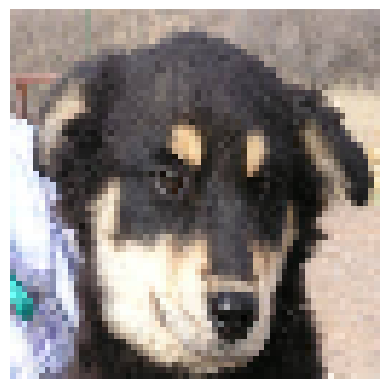

In [ ]:
import matplotlib.pyplot as plt

my_image_path = r"datasets\test\dogs\dogs_00013.jpg"
img = cv2.imread(my_image_path)

if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_resized = cv2.resize(img, (64, 64))
    X_single = img_resized.reshape(64 * 64 * 3, 1) / 255.

    my_prediction = predict(X_single, None, parameters)

    result = int(np.squeeze(my_prediction))

    print(f"Model y = {result}")
    if result == 1:
        print("=> Dog")
    else:
        print("=> Cat")
        
    plt.imshow(img_resized)
    
    plt.axis('off')
    plt.show()
else:
    print("Cannot read")
